<a href="https://colab.research.google.com/github/lilav111/CPU_Scheduling_Project/blob/main/CPU_Scheduling_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

%%writefile input.txt
6
P1 0 9 2
P2 2 7 5
P3 2 3 1
P4 2 2 1
P5 5 5 2
P6 6 5 1


Writing input.txt


In [ ]:
with open("input.txt", "r") as f:
    print(f.read())

6
P1 0 9 2
P2 2 7 5
P3 2 3 1
P4 2 2 1
P5 5 5 2
P6 6 5 1



SRTF Scheduling Results
-----------------------------------------------------------------
Process  AT  BT  CT  TAT  WT  RT
P1 0 9 24 24 15 0
P2 2 7 31 29 22 22
P3 2 3 7 5 2 2
P4 2 2 4 2 0 0
P5 5 5 12 7 2 2
P6 6 5 17 11 6 6

Average Waiting Time: 7.833333333333333
Average Turnaround Time: 13.0
Average Response Time: 5.333333333333333


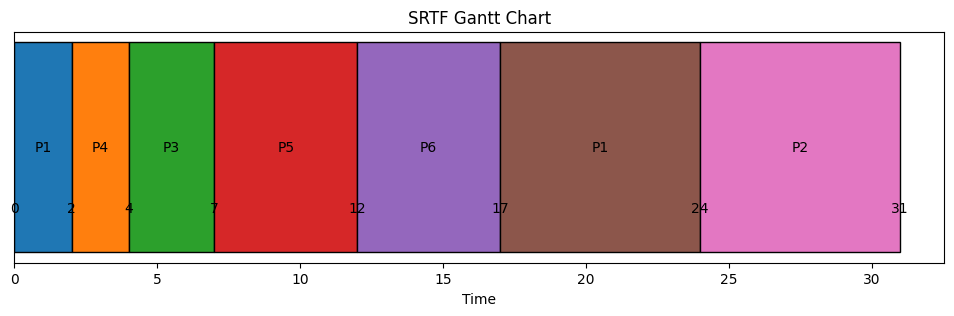

In [ ]:

import matplotlib.pyplot as plt

# قراءة بيانات العمليات
processes = []

with open("input.txt", "r") as f:
    n = int(f.readline())

    for line in f:
        pid, arrival, burst, priority = line.split()

        processes.append({
            "pid": pid,
            "arrival": int(arrival),
            "burst": int(burst),
            "remaining": int(burst),
            "response": -1,
            "completion": 0
        })

# تنفيذ خوارزمية SRTF
time = 0
completed = 0
gantt = []

while completed < n:

    available = [
        p for p in processes
        if p["arrival"] <= time and p["remaining"] > 0
    ]

    if not available:
        time += 1
        continue

    current = min(
        available,
        key=lambda p: p["remaining"]
    )

    if current["response"] == -1:
        current["response"] = time - current["arrival"]

    if gantt and gantt[-1][2] == current["pid"]:
        gantt[-1][1] += 1
    else:
        gantt.append([time, time + 1, current["pid"]])

    current["remaining"] -= 1
    time += 1

    if current["remaining"] == 0:
        current["completion"] = time
        completed += 1

# حساب الأزمنة
total_waiting = 0
total_turnaround = 0
total_response = 0

print("SRTF Scheduling Results")
print("-" * 65)
print("Process  AT  BT  CT  TAT  WT  RT")

for p in processes:
    tat = p["completion"] - p["arrival"]
    wt = tat - p["burst"]
    rt = p["response"]

    total_waiting += wt
    total_turnaround += tat
    total_response += rt

    print(p["pid"], p["arrival"], p["burst"],
          p["completion"], tat, wt, rt)

print("\nAverage Waiting Time:", total_waiting / n)
print("Average Turnaround Time:", total_turnaround / n)
print("Average Response Time:", total_response / n)

# رسم Gantt Chart
fig, ax = plt.subplots(figsize=(12, 3))

for start, end, pid in gantt:
    ax.barh(0, end-start, left=start,
            edgecolor="black")
    ax.text((start+end)/2, 0, pid,
            ha="center", va="center")

    ax.text(start, -0.25, str(start),
            ha="center")

ax.text(gantt[-1][1], -0.25, str(gantt[-1][1]),
        ha="center")

ax.set_yticks([])
ax.set_xlabel("Time")
ax.set_title("SRTF Gantt Chart")
plt.show()


FCFS Scheduling Results
-----------------------------------------------------------------
Process  AT  BT  CT  TAT  WT  RT
P1 0 9 9 9 0 0
P2 2 7 16 14 7 7
P3 2 3 19 17 14 14
P4 2 2 21 19 17 17
P5 5 5 26 21 16 16
P6 6 5 31 25 20 20

Average Waiting Time: 12.333333333333334
Average Turnaround Time: 17.5
Average Response Time: 12.333333333333334


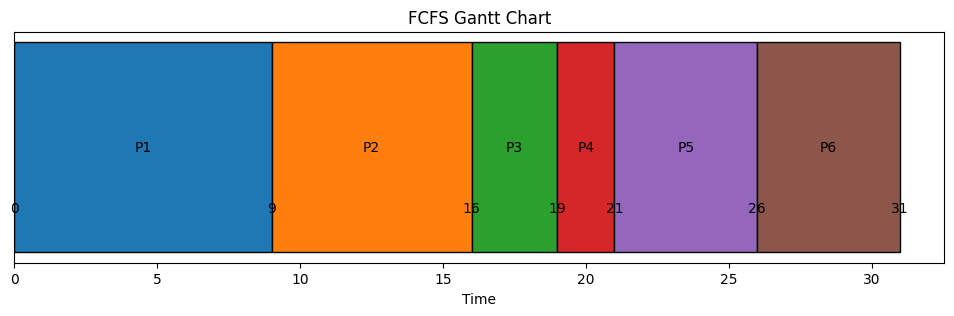

In [5]:

import matplotlib.pyplot as plt

# قراءة العمليات من الملف
processes = []

with open("input.txt", "r") as f:
    n = int(f.readline())

    for line in f:
        pid, arrival, burst, priority = line.split()

        processes.append({
            "pid": pid,
            "arrival": int(arrival),
            "burst": int(burst)
        })

# ترتيب العمليات حسب زمن الوصول
processes.sort(key=lambda p: p["arrival"])

time = 0
gantt = []

total_waiting = 0
total_turnaround = 0
total_response = 0

print("FCFS Scheduling Results")
print("-" * 65)
print("Process  AT  BT  CT  TAT  WT  RT")

for p in processes:

    if time < p["arrival"]:
        gantt.append([time, p["arrival"], "Idle"])
        time = p["arrival"]

    start = time
    time += p["burst"]

    ct = time
    tat = ct - p["arrival"]
    wt = start - p["arrival"]
    rt = wt

    total_waiting += wt
    total_turnaround += tat
    total_response += rt

    gantt.append([start, ct, p["pid"]])

    print(p["pid"], p["arrival"], p["burst"],
          ct, tat, wt, rt)

print("\nAverage Waiting Time:", total_waiting / n)
print("Average Turnaround Time:", total_turnaround / n)
print("Average Response Time:", total_response / n)

# رسم مخطط Gantt
fig, ax = plt.subplots(figsize=(12, 3))

for start, end, pid in gantt:
    ax.barh(0, end-start, left=start,
            edgecolor="black")
    ax.text((start+end)/2, 0, pid,
            ha="center", va="center")

    ax.text(start, -0.25, str(start),
            ha="center")

ax.text(gantt[-1][1], -0.25, str(gantt[-1][1]),
        ha="center")

ax.set_yticks([])
ax.set_xlabel("Time")
ax.set_title("FCFS Gantt Chart")
plt.show()


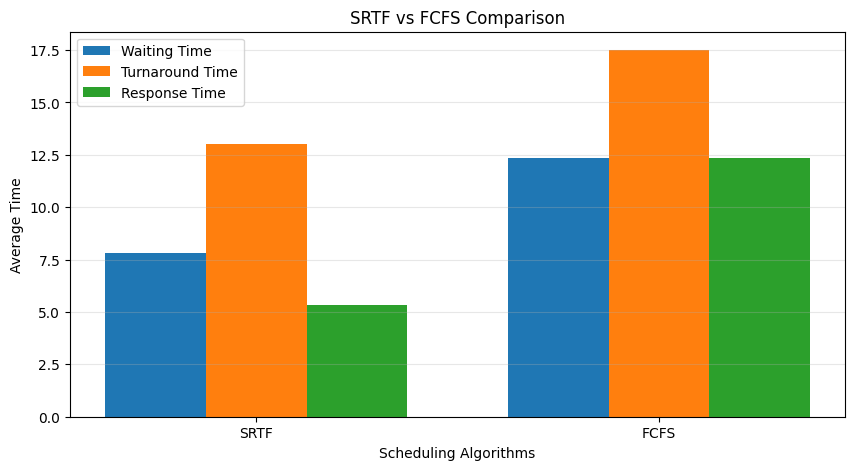

Comparison Results
------------------
SRTF Average Waiting: 7.83
FCFS Average Waiting: 12.33
SRTF Average Turnaround: 13
FCFS Average Turnaround: 17.5
SRTF Average Response: 5.33
FCFS Average Response: 12.33

SRTF performed better in all three averages.


In [6]:

import matplotlib.pyplot as plt
import numpy as np

# نتائج الخوارزميتين
algorithms = ["SRTF", "FCFS"]

waiting = [7.83, 12.33]
turnaround = [13, 17.5]
response = [5.33, 12.33]

x = np.arange(len(algorithms))
width = 0.25

plt.figure(figsize=(10, 5))

plt.bar(x - width, waiting, width, label="Waiting Time")
plt.bar(x, turnaround, width, label="Turnaround Time")
plt.bar(x + width, response, width, label="Response Time")

plt.xlabel("Scheduling Algorithms")
plt.ylabel("Average Time")
plt.title("SRTF vs FCFS Comparison")

plt.xticks(x, algorithms)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

print("Comparison Results")
print("------------------")
print("SRTF Average Waiting:", waiting[0])
print("FCFS Average Waiting:", waiting[1])
print("SRTF Average Turnaround:", turnaround[0])
print("FCFS Average Turnaround:", turnaround[1])
print("SRTF Average Response:", response[0])
print("FCFS Average Response:", response[1])

print("\nSRTF performed better in all three averages.")
